In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import matplotlib.pyplot as plt
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *

# allensdk force-downgrades numpy/pandas if installed into this env -- see
# make_0_prepare/common-functions/local_allen_cache.py. Every file this
# notebook touches is already downloaded, so this reads the same cache
# directly instead (pynrrd only, no numpy/pandas conflict). Verified
# bit-identical against this notebook's own previously stored output.
from local_allen_cache import LocalMouseConnectivityCache as MouseConnectivityCache

In [3]:
prefix = '/mnt/staging/'
figure_config_root = str(PREPARES / "config") + "/"
palatte_dict = load_pickle(figure_config_root+'palatte_dict')

In [4]:
from pathlib import Path


In [5]:

# The manifest file is a simple JSON file that keeps track of all of
# the data that has already been downloaded onto the hard drives.
# If you supply a relative path, it is assumed to be relative to your
# current working directory.
result_path = str(PREPARES / "allen-connectivity-atlas/NEW/wild-type-S1")
output_dir = result_path
mcc = MouseConnectivityCache(manifest_file=Path(output_dir) / 'manifest.json',resolution=10)

# open up a list of all of the experiments
all_experiments = mcc.get_experiments(dataframe=True)
print("%d total experiments" % len(all_experiments))

# take a look at what we know about an experiment with a primary motor injection
all_experiments.loc[114290938]

2992 total experiments


gender                                                         M
injection_structures                                       [345]
injection_volume                                        0.368922
injection_x                                                 4530
injection_y                                                 2470
injection_z                                                 8980
product_id                                                     5
specimen_name                                           378-1165
strain                                                  C57BL/6J
structure_abbrev                                           SSp-m
structure_id                                                 345
structure_name                 Primary somatosensory area, mouth
transgenic_line                                             None
transgenic_line_id                                           NaN
id                                                     114290938
primary_injection_structu

In [18]:
S1_experiment_ids = {
    "VISp": 307558646,
    # "SSp-m": 114290938, #wild type option 1
    "SSp-m":112162251, #wild type option 2
    # "SSp-m":181819064, # Scnn1a-Tg3-Cre
    "SSp-n": 126908007,
    # "SSp-ul": 112229814, #wild type
    "SSp-ul":286312782, #Rbp4-Cre_KL100
    "SSp-ll": 112935169,
    "SSp-bfd": 127866392
}

In [19]:
dict_ind = {}
dict_ind_info = {}
dict_pd = {}
dict_pd_info = {}
for key in S1_experiment_ids:
    experiment_id = S1_experiment_ids[key]
    # injection density: number of projecting pixels in injection site / voxel volume
    ind, ind_info = mcc.get_injection_density(experiment_id) 
    dict_ind[key] = ind
    dict_ind_info[key] = ind_info
    # projection density: number of projecting pixels / voxel volume
    pd, pd_info = mcc.get_projection_density(experiment_id)
    dict_pd[key]=pd
    dict_pd_info[key]=pd_info
    

(1200.0, 160.0)

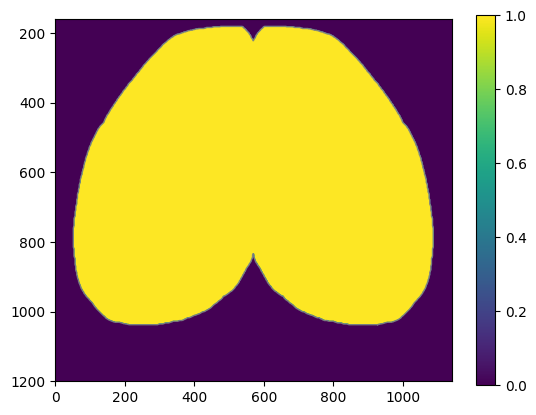

In [20]:
# in addition to the annotation volume, you can get binary masks for individual structures
# in this case, we'll get one for the isocortex
cortex_mask, cm_info = mcc.get_structure_mask(315)

cortex_mask_mip = cortex_mask.max(axis=1)

from skimage import measure
brain_contours = measure.find_contours(cortex_mask_mip>0.5, level=0.5)

    
plt.imshow(cortex_mask_mip)
plt.colorbar()
for contour in brain_contours:
    plt.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.9)
# plt.xlim([20,436])
plt.ylim([1200,160])

In [21]:
dict_coord={}
dict_S1_contour = {}
from scipy.ndimage import center_of_mass
for key in S1_experiment_ids:
    dict_coord[key] = center_of_mass(dict_ind[key].max(axis=1))
    S1_contours = measure.find_contours(dict_ind[key].max(axis=1)>0.5, level=0.5)
    dict_S1_contour[key] = S1_contours

In [13]:
from save_dict_to_hdf5 import *
            
save_dict_to_hdf5(dict_pd,result_path+'/wild_type_S1.h5')


## load tif file with 4D volume (3D x channels)

In [23]:
import tifffile as tiff
fileroot = str(PREPARES / "allen-connectivity-atlas") + "/"
filepath = fileroot + 'merged_wild_type_S1_masked.tif'
with tiff.TiffFile(filepath) as tif:
    arr = tif.asarray()  # shape: (Z, Y, X, C) or (Y, X, Z*C)
cortical_projection=arr.transpose((0,2,1,3))

# load brain mask
filepath = fileroot + 'brain_mask.tif'
with tiff.TiffFile(filepath) as tif:
    arr = tif.asarray()  # shape: (Z, Y, X, C) or (Y, X, Z*C)
cortical_mask=arr.transpose((0,2,1))

print("Loaded shape:", cortical_projection.shape)

Loaded shape: (1320, 800, 1140, 6)


In [24]:
import skimage
from skimage.transform import resize

# Downsample a single volume (z, y, x)
def downsample(vol, scale=0.25):
    return resize(vol, 
                  output_shape=tuple([int(s * scale) for s in vol.shape]),
                  preserve_range=True,
                  anti_aliasing=True).astype(vol.dtype)

# # Apply to all projection volumes
proj_channels_ds = np.stack([downsample(cortical_projection[..., i]) for i in range(6)], axis=-1)
brain_mask_ds = downsample(cortical_mask)
brain_mask_ds = (brain_mask_ds.astype('float')*65536).astype('int')

In [26]:
brain_mask_ds = brain_mask_ds.transpose((0,2,1))
proj_channels_ds = proj_channels_ds.transpose((0,2,1,3))

# Make figure

In [27]:
from matplotlib.colors import LinearSegmentedColormap

from matplotlib.colors import LinearSegmentedColormap, to_rgb

def make_dynamic_cmap(hex_color, name):
    base_rgb = to_rgb(hex_color)
    
    # Add a middle point (scaled up to boost intensity)
    # boosted = tuple(min(1, c * 2) for c in base_rgb)
    boost = 2
    boosted = tuple(min(1.0, c * boost + 0.2 * (1 - c)) for c in base_rgb)
    return LinearSegmentedColormap.from_list(name, ['black', boosted, 'white'])


cmap_dict = {key: make_dynamic_cmap(color, key) for key, color in palatte_dict.items()}


In [28]:
dict_scaling_factor= {
    "VISp": 1,
    "SSp-m": 1,
    "SSp-n": 1,
    "SSp-ul": 1,
    "SSp-ll": 1,
    "SSp-bfd": 1
                     }


bdp_short_dict = {'LFP':'SSp-ul','LHP':'SSp-ll','LM':'SSp-m','LW':'SSp-bfd',
                  'LN':'SSp-n','LV':'VISp'}

dict_bdp_w_order = {'SSp-bfd':0,'SSp-ll':1,'SSp-m':2,'SSp-n':3,'SSp-ul':4,'VISp':5}

In [29]:
import pandas as pd
print("Fetching precise injection coordinates...")
experiments_df = pd.DataFrame(mcc.get_experiments())

dict_coord_api = {}
for bdp, exp_id in S1_experiment_ids.items():
    # Find the row for this specific experiment
    row = experiments_df[experiments_df['id'] == exp_id].iloc[0]
    
    # Allen API returns coordinates in micrometers (um)
    # Divide by 10 to match your 10um dict_pd voxel grid!
    # AP = injection_x (maps to y-axis in imshow)
    # ML = injection_z (maps to x-axis in imshow)
    ap_plot = row['injection_x'] / 10.0
    ml_plot = row['injection_z'] / 10.0
    
    # Store as (AP, ML) to match your loop's expectation of [0] and [1]
    dict_coord_api[bdp] = (ap_plot, ml_plot)

Fetching precise injection coordinates...


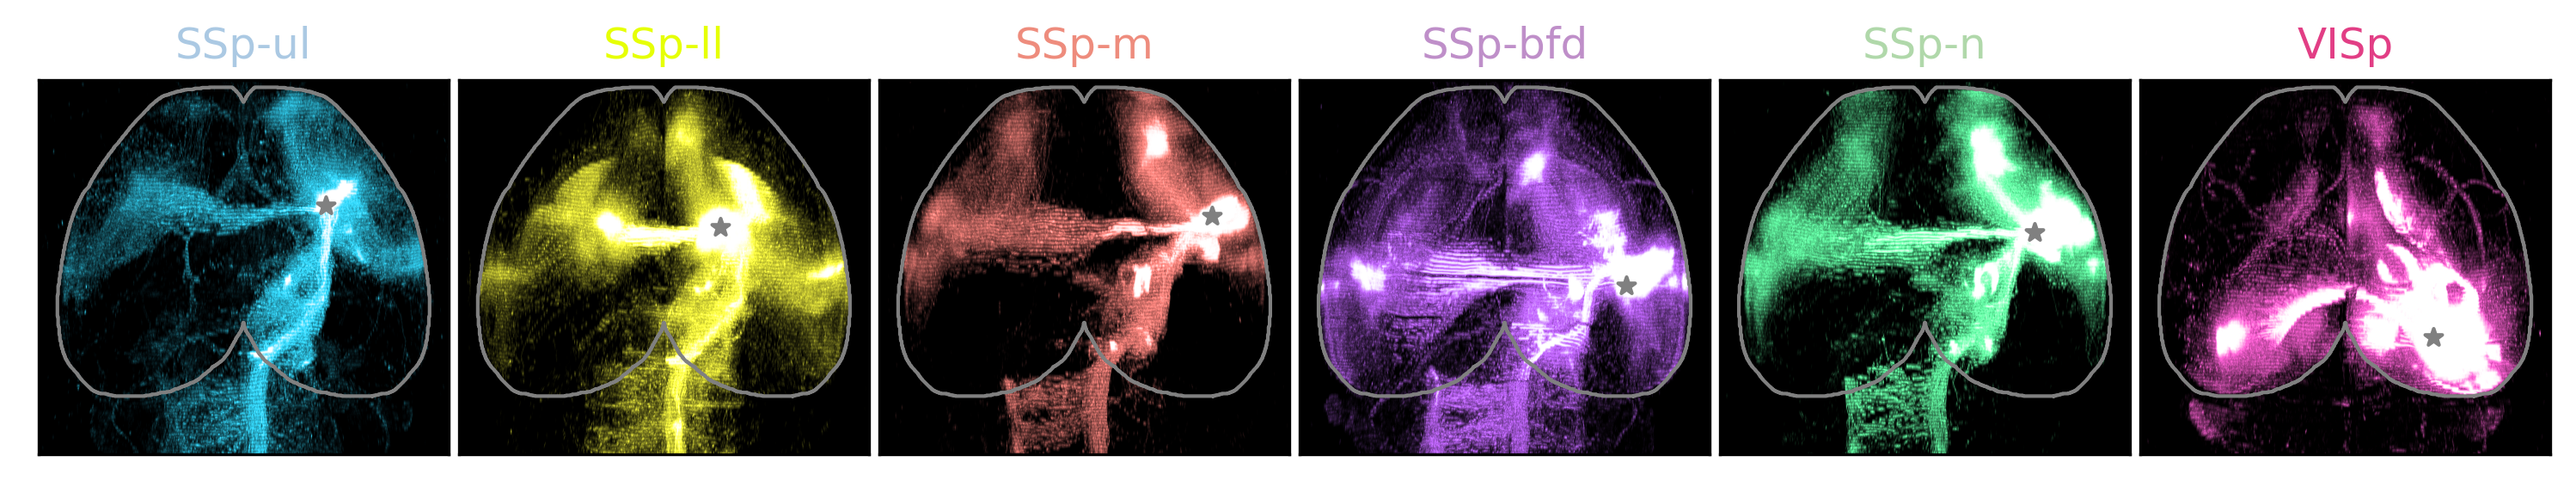

In [32]:
from matplotlib import colors
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)


y_offset = 20;x_offset=20;y_gap=1;x_gap=0;x_width=6

x_start = x_offset
for i_ax in range(6):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+7,x_start:x_start+7])".format(i_ax))
    x_start = x_start+7+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    


bdp_short_dict = {'LFP':'SSp-ul','LHP':'SSp-ll','LM':'SSp-m','LW':'SSp-bfd',
                  'LN':'SSp-n','LV':'VISp'}

dict_bdp_w_order = {'SSp-bfd':0,'SSp-ll':1,'SSp-m':2,'SSp-n':3,'SSp-ul':4,'VISp':5}

################################################
for i_bdp,bdp in enumerate(['SSp-ul','SSp-ll','SSp-m','SSp-bfd','SSp-n','VISp']):
    ind_here = dict_bdp_w_order[bdp]
    # pd_mip = arr[:,:,:,ind_here].max(axis=1)
    pd_mip = dict_pd[bdp].max(axis=1)
    
    key = next((k for k, v in bdp_short_dict.items() if v == bdp), None)
    exec("ax{}.imshow(pd_mip*dict_scaling_factor[bdp],cmap=cmap_dict[key.replace('L','R')],vmin=0,vmax=1)".format(i_bdp))
    exec("ax{}.set_title(bdp,color=palatte_dict[key])".format(i_bdp))

    for contour in brain_contours:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=1)".format(i_bdp))
    exec("ax{}.scatter(dict_coord_api[bdp][1],dict_coord_api[bdp][0],marker='*', s=25, c='gray', zorder=2)".format(i_bdp))

        
for i_key in range(6):    
    exec("ax{}.set_ylim([1200,160])".format(i_key))
    
plt.savefig('fig4-S1-seeded-allen-connectivity-atlas-MIP.svg',format='svg',dpi=300)

# Merge and slice

In [176]:
dict_bdps_w_order = {'LW':0,'LV':5,'LN':3,'LM':2,'LHP':1,'LFP':4}


In [35]:
# Precompute MIPs for body parts and store in a dict
precomputed_mips = {}

for label in bdp_w_order:
    i_order = dict_bdps_w_order[label]
    vol_mip = np.mean(cortical_projection[..., i_order], axis=1)  # shape: (1320, 1140)
    precomputed_mips[label] = vol_mip


**Compose colors**

In [289]:
dict_scaling_factor= {'LW':2,'LV':1.5,'LN':1,'LM':1,'LFP':1,'LHP':1}
bdp_w_order = ['LV','LW','LN','LM']


In [290]:
import matplotlib.colors as mcolors

# Preprocess: convert hex palette to RGB array
# rgb_palette = {
#     k: np.array(mcolors.to_rgb(v), dtype=np.float32)
#     for k, v in palatte_dict.items()
# }

import colorsys

def boost_color(hex_color, sat_boost=1, light_boost=1):
    """Boosts saturation and lightness of a hex color"""
    rgb = mcolors.to_rgb(hex_color)
    h, l, s = colorsys.rgb_to_hls(*rgb)
    s = min(s * sat_boost, 1.0)
    l = min(l * light_boost, 1.0)
    boosted_rgb = colorsys.hls_to_rgb(h, l, s)
    return np.array(boosted_rgb, dtype=np.float32)

rgb_palette = {
    k: boost_color(v) for k, v in palatte_dict.items()
}


# Start with 80% white base from structural mask
brain_mask_norm = (brain_mask_ds / brain_mask_ds.max()).astype(np.float32)
composite_rgb = np.empty((*brain_mask_ds.shape, 3), dtype=np.float32)
# for c in range(3):
#     composite_rgb[..., c] = brain_mask_norm * 0.8  # white background


# STEP 1: Blend all projections with their unique scaling factor
for label in bdp_w_order:
    # Use label_r for both color and scale for consistency
    label_r = label.replace('L', 'R')
    color = rgb_palette[label_r]
    i_order = dict_bdps_w_order[label]
    scale = dict_scaling_factor.get(label, 1.0) # BUG FIX: Use label_r to get the scale

    vol = proj_channels_ds[..., i_order]  # (Y, Z, X)

    # Blend the scaled volume into the composite image
    for c in range(3):
        composite_rgb[..., c] += vol * color[c] * scale 
        
# STEP 2: Normalize the final result instead of clipping
if composite_rgb.max() > 0:
    composite_rgb /= composite_rgb.max()

# composite_rgb = np.clip(composite_rgb, 0, 1)
# gamma = 0.6  # <1.0 brightens midtones
# composite_rgb = composite_rgb ** gamma

brightness_boost = 1.5  # You can adjust this
composite_rgb *= brightness_boost
composite_rgb = np.clip(composite_rgb, 0, 1)


/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:12: RuntimeWarning: Mean of empty slice
  if sys.path[0] == '':


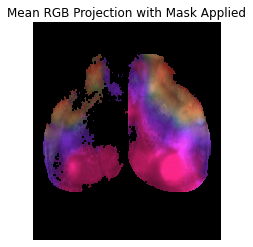

In [291]:
import numpy as np
import matplotlib.pyplot as plt

# Apply mask: compute mean across RGB channels
mask = composite_rgb.mean(axis=-1) < 0.2  # shape (330, 285, 200)

# Broadcast mask to last dimension (RGB)
composite_rgb_masked = composite_rgb.copy()
composite_rgb_masked[mask] = np.nan  # set all channels to nan where mask is True

# Compute nanmean along axis=2 (depth)
composite_rgb_mean = np.nanmean(composite_rgb_masked, axis=2)  # shape (330, 285, 3)

# Plot using imshow
plt.imshow(composite_rgb_mean)
plt.axis('off')
plt.title("Mean RGB Projection with Mask Applied")
plt.show()


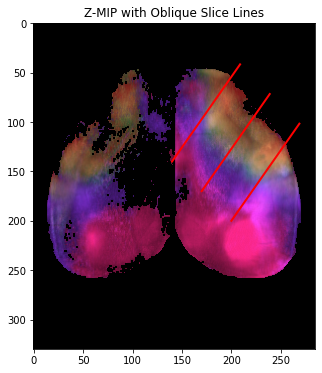

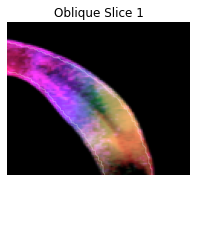

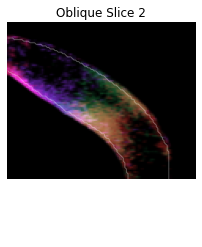

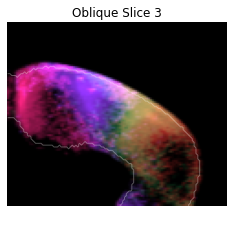

In [292]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

# Assume brain_mask_ds is already loaded (y, x, z)
height, width, depth = brain_mask_ds.shape
num_slices = 3
angle_deg = 55
angle_rad = np.deg2rad(angle_deg)

# Oblique plane parameters
plane_width = 120   # width of the oblique slice (in-plane)
plane_height = 200  # height of the oblique slice (in-plane)

# Direction vector for plane (unit vector in x-y)
dx = np.cos(angle_rad)
dy = -np.sin(angle_rad)  # negative slope: y decreases as x increases

# Spacing between planes
slice_spacing = 20
y_base = height - 1 - 120
y_step = 30
x_step = 30

# Display MIP + slice lines
plt.figure(figsize=(10, 6))
# mip = np.max(proj_channels_ds[...,0], axis=2)
# plt.imshow(mip, cmap='gray')
plt.imshow(composite_rgb_mean)
plt.title("Z-MIP with Oblique Slice Lines")

oblique_slices = []
contours = {}
for i in range(num_slices):
    # Origin of oblique plane
    x0 = 200 - i * x_step
    y0 = 200 - i * y_step
    z0 = 0  # start from shallow z (can change if needed)

    # Generate grid in the oblique 2D plane
    # u: along the 45° axis (diagonal); v: orthogonal (into depth)
    u = np.linspace(0, plane_width - 1, plane_width)
    v = np.linspace(0, plane_height - 1, plane_height)
    uu, vv = np.meshgrid(u, v)

    # Direction vectors for u and v axes
    u_vec = np.array([dy, dx])            # u: diagonal (y, x)
    v_vec = np.array([0, 0, 1])           # v: depth (z)

    # Build coordinates in 3D space
    x_coords = x0 + uu * dx
    y_coords = y0 + uu * dy
    z_coords = vv + z0

    # Clip coordinates to volume bounds
    x_coords = np.clip(x_coords, 0, width - 1)
    y_coords = np.clip(y_coords, 0, height - 1)
    z_coords = np.clip(z_coords, 0, depth - 1)

    # --- START: MODIFIED CODE ---

    # Create the 3D coordinate array (y, x, z)
    coords = np.vstack([y_coords.ravel(), x_coords.ravel(), z_coords.ravel()])
    
    # Sample each color channel independently from the 4D volume
    sampled_channels = []
    for channel_index in range(composite_rgb.shape[3]):
        # Sample from one 3D channel at a time
        sampled_channel = map_coordinates(composite_rgb[..., channel_index], coords, order=1, mode='nearest')
        sampled_channels.append(sampled_channel.reshape(plane_height, plane_width))

    # Stack the sampled channels back into an RGB image (height, width, 3)
    slice_img = np.stack(sampled_channels, axis=-1)
    
    # --- END: MODIFIED CODE ---
    oblique_slices.append(slice_img)

    # Visualize slice line on MIP
    line_x = [x0, x0 + dx * plane_width]
    line_y = [y0, y0 + dy * plane_width]
    plt.plot(line_x, line_y, color='red', linewidth=2)

    
    # add cortical mask
    from skimage import measure

    # Resample mask with same coords
    sampled_mask = map_coordinates(brain_mask_ds.astype(np.float32), coords, order=1, mode='nearest')
    slice_mask = sampled_mask.reshape(plane_height, plane_width)

    # Binary threshold to define the brain region
    binary_mask = slice_mask > 0.5  # or try 0.1 depending on your mask scale

    # Find contours in the 2D slice (returns list of Nx2 arrays)
    contours[i] = measure.find_contours(binary_mask, level=0.5)


plt.show()

# Display extracted oblique slices
for i, slice_img in enumerate(oblique_slices):
    plt.figure()
    plt.title(f'Oblique Slice {i+1}')
    plt.imshow(slice_img[:100,:,:])
    plt.axis('off')
    for contour in contours[i]:
        plt.plot(contour[:, 1], contour[:, 0], color='white', linewidth=1, alpha=0.3)
        


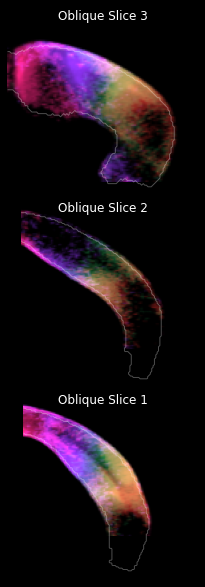

In [299]:
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'

# --- START: MODIFIED CODE ---

# Define the grid layout for the subplots (e.g., 2 rows, 2 columns for 4 slices)
nrows = 3
ncols = 1

# Create a figure and a set of subplots
fig, axes = plt.subplots(nrows, ncols, figsize=(10, 8), facecolor='black')

# Flatten the axes array for easy iteration
axes = axes.flatten()

for i, slice_img in enumerate(oblique_slices):
    # Get the specific subplot axis for the current slice
    ax = axes[2-i]

    ax.set_title(f'Oblique Slice {i+1}', color='white',y=0.9)
    ax.imshow(slice_img[:110,:,:])
    ax.axis('off')

    # Plot contours on the corresponding subplot
    for contour in contours[i]:
        ax.plot(contour[:, 1], contour[:, 0], color='white', linewidth=1, alpha=0.3)

# Hide any unused subplots if the number of slices is less than the grid size
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

# Adjust layout to prevent titles from overlapping
plt.tight_layout(pad=0)

# Save the entire figure with 300 DPI resolution
# bbox_inches='tight' removes extra white space around the figure
plt.savefig('fig4-oblique_slices_comparison.svg', dpi=300, bbox_inches='tight')

# Display the figure
plt.show()

# --- END: MODIFIED CODE ---

# now forepaw and hindpaw

In [300]:
dict_scaling_factor= {'LFP':1.2,'LHP':0.7}
bdp_w_order = ['LFP','LHP']


In [301]:
# Start with 80% white base from structural mask
brain_mask_norm = (brain_mask_ds / brain_mask_ds.max()).astype(np.float32)
composite_rgb = np.empty((*brain_mask_ds.shape, 3), dtype=np.float32)
# for c in range(3):
#     composite_rgb[..., c] = brain_mask_norm * 0.8  # white background


# STEP 1: Blend all projections with their unique scaling factor
for label in bdp_w_order:
    # Use label_r for both color and scale for consistency
    label_r = label.replace('L', 'R')
    color = rgb_palette[label_r]
    i_order = dict_bdps_w_order[label]
    scale = dict_scaling_factor.get(label, 1.0) # BUG FIX: Use label_r to get the scale

    vol = proj_channels_ds[..., i_order]  # (Y, Z, X)

    # Blend the scaled volume into the composite image
    for c in range(3):
        composite_rgb[..., c] += vol * color[c] * scale 
        
# STEP 2: Normalize the final result instead of clipping
if composite_rgb.max() > 0:
    composite_rgb /= composite_rgb.max()

# composite_rgb = np.clip(composite_rgb, 0, 1)
# gamma = 0.6  # <1.0 brightens midtones
# composite_rgb = composite_rgb ** gamma

brightness_boost = 1.5  # You can adjust this
composite_rgb *= brightness_boost
composite_rgb = np.clip(composite_rgb, 0, 1)


/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:12: RuntimeWarning: Mean of empty slice
  if sys.path[0] == '':


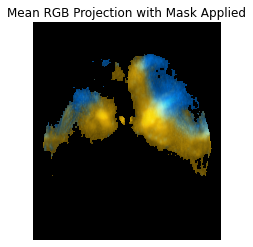

In [302]:
import numpy as np
import matplotlib.pyplot as plt

# Apply mask: compute mean across RGB channels
mask = composite_rgb.mean(axis=-1) < 0.2  # shape (330, 285, 200)

# Broadcast mask to last dimension (RGB)
composite_rgb_masked = composite_rgb.copy()
composite_rgb_masked[mask] = np.nan  # set all channels to nan where mask is True

# Compute nanmean along axis=2 (depth)
composite_rgb_mean = np.nanmean(composite_rgb_masked, axis=2)  # shape (330, 285, 3)

# Plot using imshow
plt.imshow(composite_rgb_mean)
plt.axis('off')
plt.title("Mean RGB Projection with Mask Applied")
plt.show()


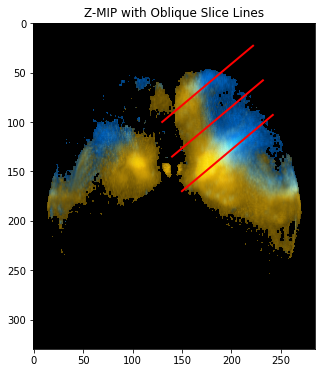

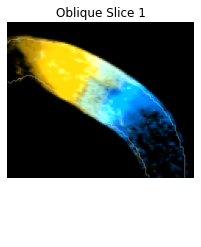

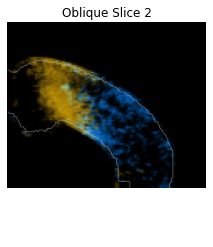

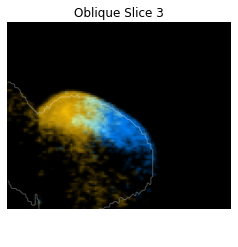

In [303]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

# Assume brain_mask_ds is already loaded (y, x, z)
height, width, depth = brain_mask_ds.shape
num_slices = 3
angle_deg = 40
angle_rad = np.deg2rad(angle_deg)

# Oblique plane parameters
plane_width = 120   # width of the oblique slice (in-plane)
plane_height = 200  # height of the oblique slice (in-plane)

# Direction vector for plane (unit vector in x-y)
dx = np.cos(angle_rad)
dy = -np.sin(angle_rad)  # negative slope: y decreases as x increases

# Spacing between planes
slice_spacing = 20
y_base = height - 1 - 120
y_step = 35
x_step = 10

# Display MIP + slice lines
plt.figure(figsize=(10, 6))
# mip = np.max(proj_channels_ds[...,0], axis=2)
# plt.imshow(mip, cmap='gray')
plt.imshow(composite_rgb_mean)
plt.title("Z-MIP with Oblique Slice Lines")

oblique_slices = []
contours = {}
for i in range(num_slices):
    # Origin of oblique plane
    x0 = 150 - i * x_step
    y0 = 170 - i * y_step
    z0 = 0  # start from shallow z (can change if needed)

    # Generate grid in the oblique 2D plane
    # u: along the 45° axis (diagonal); v: orthogonal (into depth)
    u = np.linspace(0, plane_width - 1, plane_width)
    v = np.linspace(0, plane_height - 1, plane_height)
    uu, vv = np.meshgrid(u, v)

    # Direction vectors for u and v axes
    u_vec = np.array([dy, dx])            # u: diagonal (y, x)
    v_vec = np.array([0, 0, 1])           # v: depth (z)

    # Build coordinates in 3D space
    x_coords = x0 + uu * dx
    y_coords = y0 + uu * dy
    z_coords = vv + z0

    # Clip coordinates to volume bounds
    x_coords = np.clip(x_coords, 0, width - 1)
    y_coords = np.clip(y_coords, 0, height - 1)
    z_coords = np.clip(z_coords, 0, depth - 1)

    # --- START: MODIFIED CODE ---

    # Create the 3D coordinate array (y, x, z)
    coords = np.vstack([y_coords.ravel(), x_coords.ravel(), z_coords.ravel()])
    
    # Sample each color channel independently from the 4D volume
    sampled_channels = []
    for channel_index in range(composite_rgb.shape[3]):
        # Sample from one 3D channel at a time
        sampled_channel = map_coordinates(composite_rgb[..., channel_index], coords, order=1, mode='nearest')
        sampled_channels.append(sampled_channel.reshape(plane_height, plane_width))

    # Stack the sampled channels back into an RGB image (height, width, 3)
    slice_img = np.stack(sampled_channels, axis=-1)
    
    # --- END: MODIFIED CODE ---
    oblique_slices.append(slice_img)

    # Visualize slice line on MIP
    line_x = [x0, x0 + dx * plane_width]
    line_y = [y0, y0 + dy * plane_width]
    plt.plot(line_x, line_y, color='red', linewidth=2)

    
    # add cortical mask
    from skimage import measure

    # Resample mask with same coords
    sampled_mask = map_coordinates(brain_mask_ds.astype(np.float32), coords, order=1, mode='nearest')
    slice_mask = sampled_mask.reshape(plane_height, plane_width)

    # Binary threshold to define the brain region
    binary_mask = slice_mask > 0.5  # or try 0.1 depending on your mask scale

    # Find contours in the 2D slice (returns list of Nx2 arrays)
    contours[i] = measure.find_contours(binary_mask, level=0.5)


plt.show()

# Display extracted oblique slices
for i, slice_img in enumerate(oblique_slices):
    plt.figure()
    plt.title(f'Oblique Slice {i+1}')
    plt.imshow(slice_img[:100,:,:])
    plt.axis('off')
    for contour in contours[i]:
        plt.plot(contour[:, 1], contour[:, 0], color='white', linewidth=1, alpha=0.3)

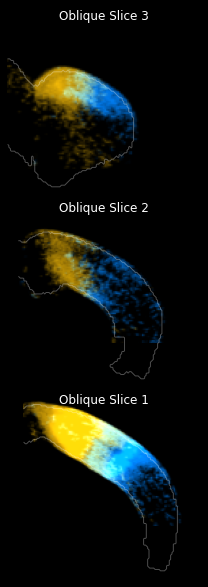

In [304]:



# --- START: MODIFIED CODE ---

# Define the grid layout for the subplots (e.g., 2 rows, 2 columns for 4 slices)
nrows = 3
ncols = 1

# Create a figure and a set of subplots
fig, axes = plt.subplots(nrows, ncols, figsize=(10, 8), facecolor='black')

# Flatten the axes array for easy iteration
axes = axes.flatten()

for i, slice_img in enumerate(oblique_slices):
    # Get the specific subplot axis for the current slice
    ax = axes[2-i]

    ax.set_title(f'Oblique Slice {i+1}', color='white',y=0.9)
    ax.imshow(slice_img[:100,:,:])
    ax.axis('off')

    # Plot contours on the corresponding subplot
    for contour in contours[i]:
        ax.plot(contour[:, 1], contour[:, 0], color='white', linewidth=1, alpha=0.3)

# Hide any unused subplots if the number of slices is less than the grid size
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.rcParams['svg.fonttype'] = 'none'
# Adjust layout to prevent titles from overlapping
plt.tight_layout(pad=0)

# Save the entire figure with 300 DPI resolution
# bbox_inches='tight' removes extra white space around the figure
plt.savefig('fig4-oblique_slices_comparison_FPHP.svg', dpi=300, bbox_inches='tight')

# Display the figure
plt.show()

# --- END: MODIFIED CODE ---


